# [Prerequisite Learning Dataset](https://github.com/itsshivampal/Prerequisite-Learning-Dataset/tree/master)

## Preqs graph

Saved figure to ../data/interim/PLD/Geometry/labeled_pairs.png


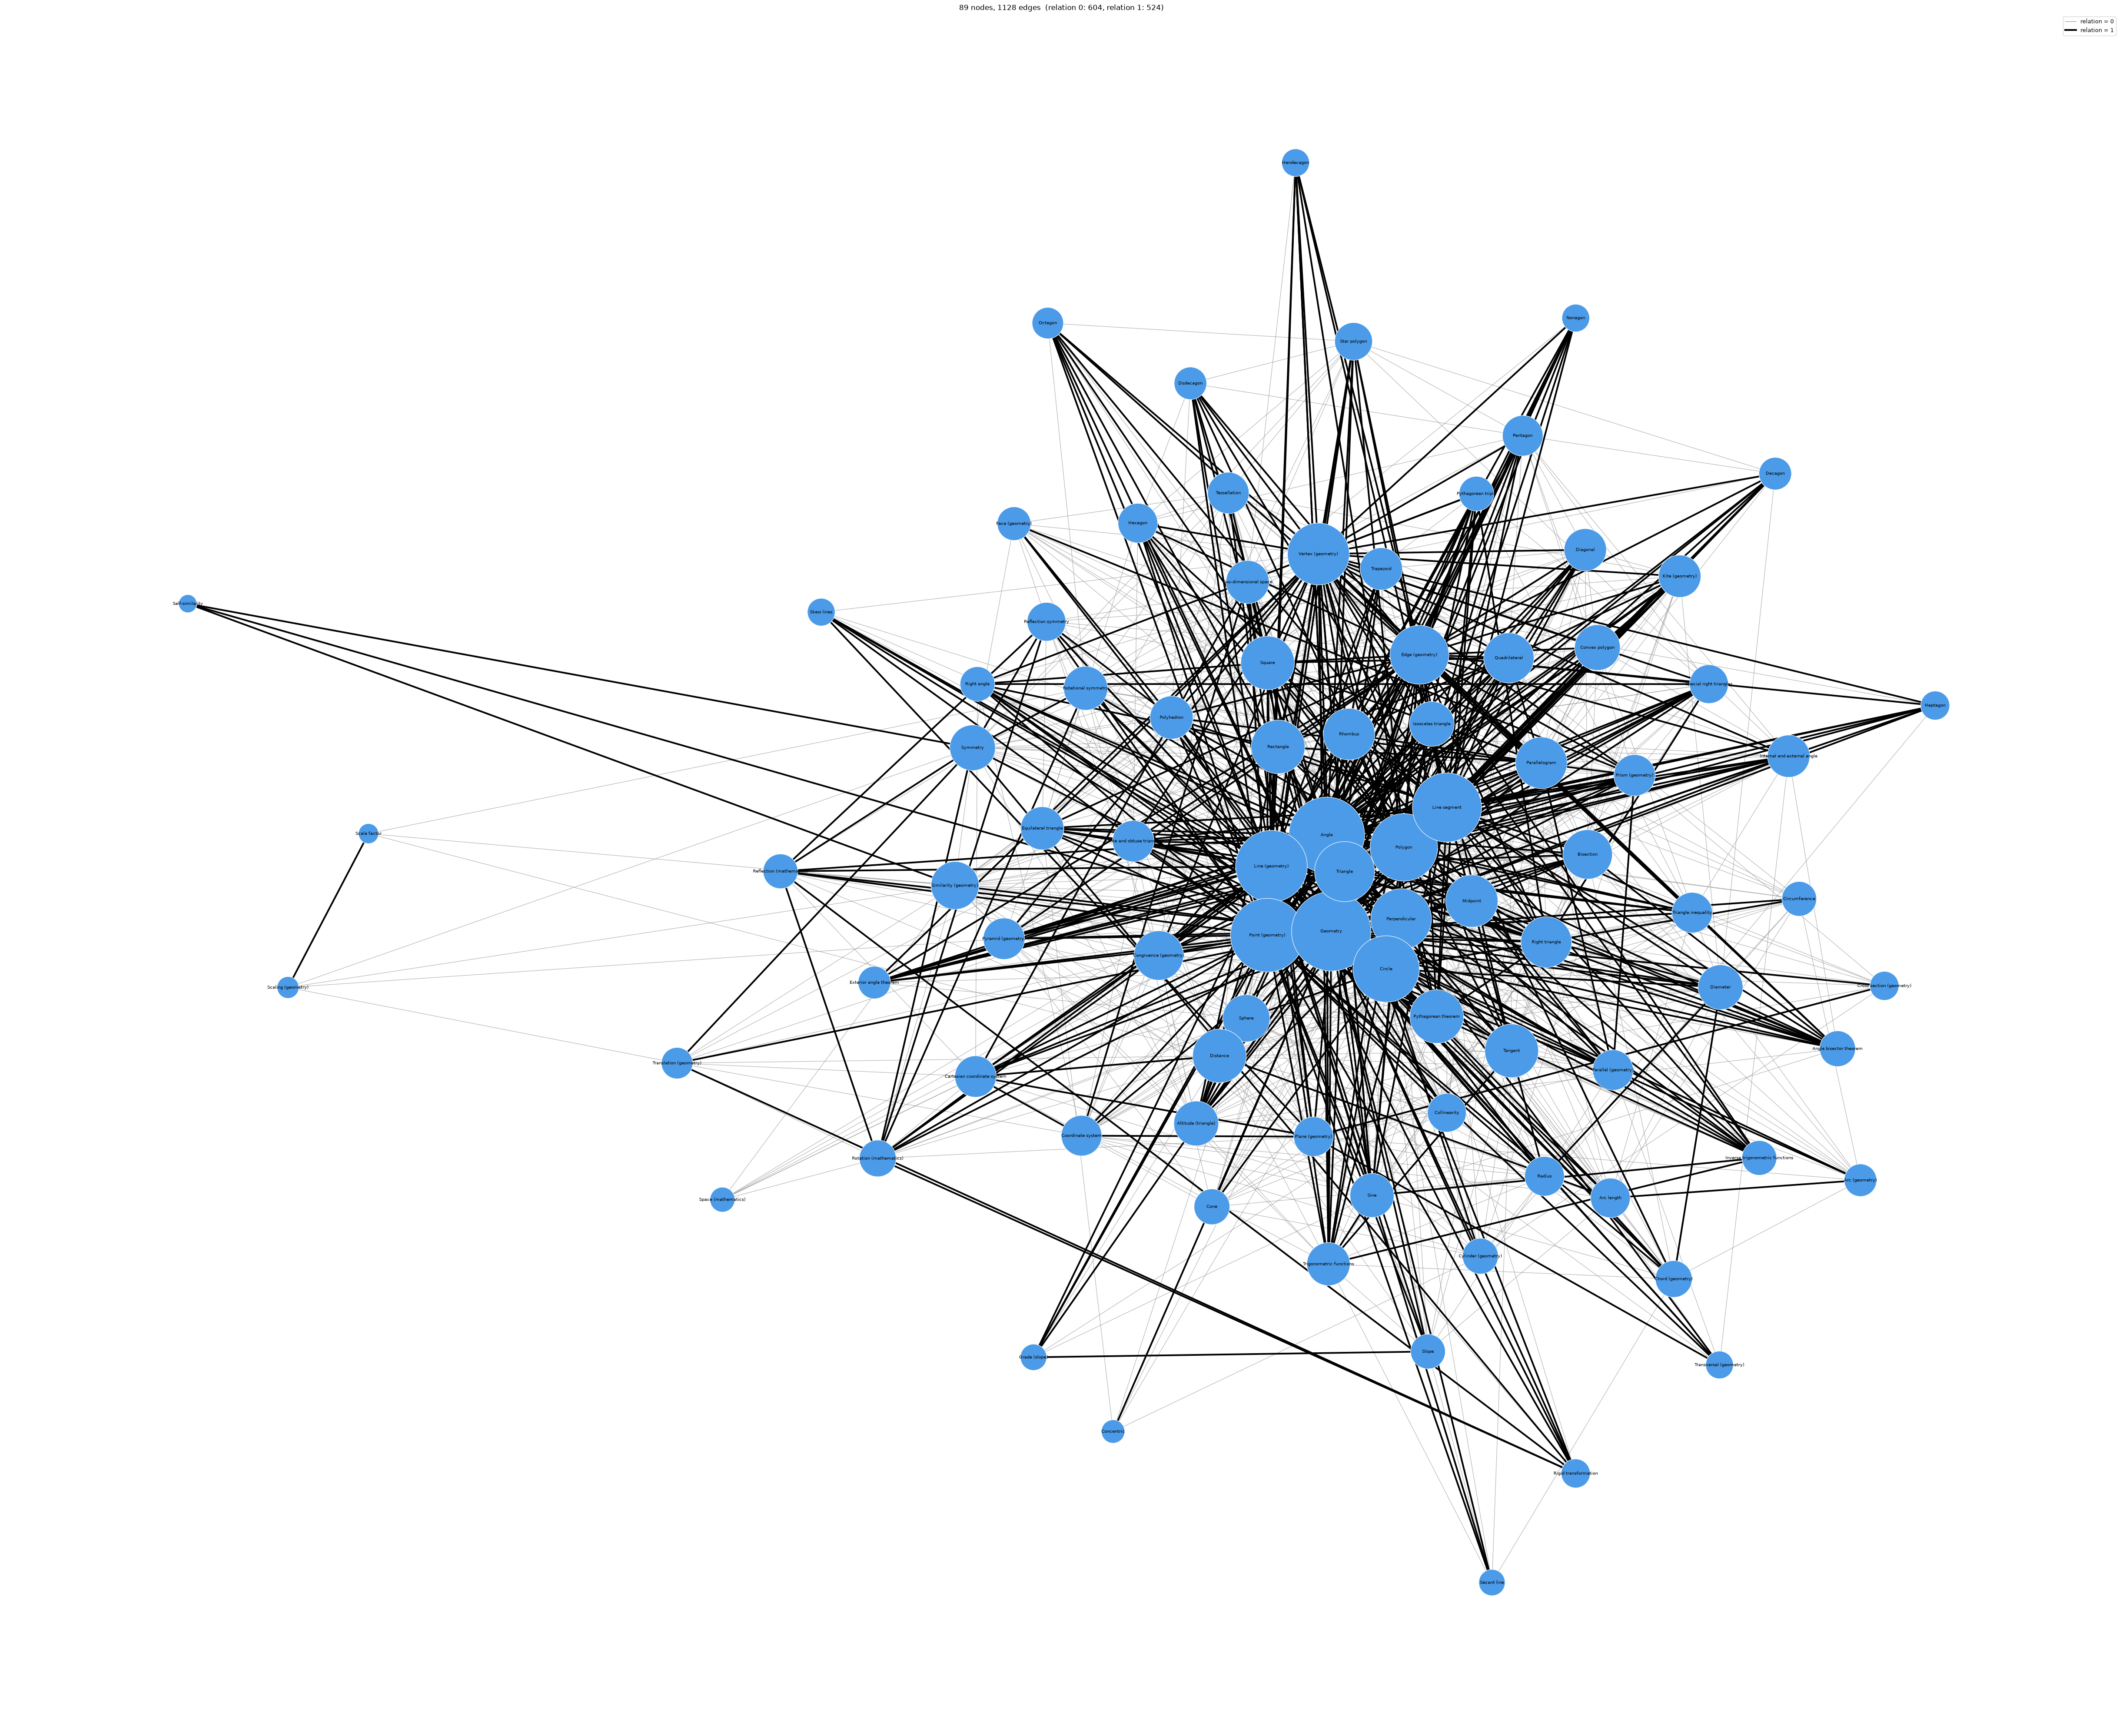

In [60]:
import sys
import csv
import math
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

infile = "../data/raw/PLD/Geometry/geometry_labeled_pairs.csv"
outfile = "../data/interim/PLD/Geometry/labeled_pairs.png"
G = nx.Graph()
rel = {}
with open(infile, newline="", encoding="utf-8") as f:
    reader = csv.DictReader(f)
    # tolerate a leading unnamed index column: DictReader skips it automatically
    for row in reader:
        a = (row["topic_a"] or "").strip()
        b = (row["topic_b"] or "").strip()
        if not a or not b:
            continue
        r = (row["relation"] or "").strip()
        r = int(r) if r not in ("", None) else 0
        w = 0.1 if r == 1 else 1.0
        G.add_edge(a, b, weight=w, relation=r)
        # if the same pair appears twice, keep the "stronger" relation
        key = frozenset((a, b))
        rel[key] = max(rel.get(key, 0), r)

n = G.number_of_nodes()
if n == 0:
    print("No edges found – nothing to draw.")

pos = nx.spring_layout(G, seed=42, k=1.6 / math.sqrt(n), iterations=500,weight="weight")

# Split edges by relation
edges_0 = [tuple(e) for e in G.edges() if rel[frozenset(e)] == 0]
edges_1 = [tuple(e) for e in G.edges() if rel[frozenset(e)] == 1]

sizes = [300 + 200 * G.degree(node) for node in G.nodes()]
labels = {node: node for node in G.nodes()}

fig, ax = plt.subplots(figsize=(max(11, n * 0.55), max(8, n * 0.45)))

# relation = 0 : thin gray
nx.draw_networkx_edges(G, pos, ax=ax, edgelist=edges_0,
                        edge_color="#999999", width=0.9, alpha=0.7)

# relation = 1 : thick black (drawn on top)
nx.draw_networkx_edges(G, pos, ax=ax, edgelist=edges_1,
                        edge_color="black", width=2.8, alpha=1.0)

nx.draw_networkx_nodes(G, pos, ax=ax, node_size=sizes,
                        node_color="#4C9BE8", edgecolors="white",
                        linewidths=0.8)
nx.draw_networkx_labels(G, pos, labels=labels, ax=ax, font_size=7)

legend = [
    Line2D([0], [0], color="#999999", lw=0.9, label="relation = 0"),
    Line2D([0], [0], color="black", lw=2.8, label="relation = 1"),
]
ax.legend(handles=legend, loc="best", frameon=True, fontsize=9)
ax.set_title(
    f"{G.number_of_nodes()} nodes, {G.number_of_edges()} edges  "
    f"(relation 0: {len(edges_0)}, relation 1: {len(edges_1)})"
)
ax.axis("off")
fig.tight_layout()
fig.savefig(outfile, dpi=200, bbox_inches="tight")
print(f"Saved figure to {outfile}")
plt.show()

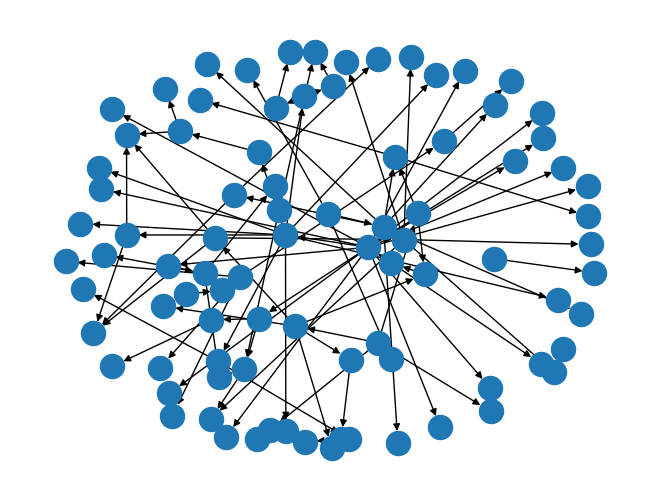

In [56]:
def to_dag(G_undirected, relation_attr="relation"):
    """
    Orient each undirected edge using a heuristic so the result is acyclic.
    Swap this for your real semantics when you have them
    (e.g. "general → specific", "part → whole", relation=1 → relation=0 ...).
    """
    D = nx.DiGraph()
    D.add_nodes_from(G_undirected.nodes(data=True))
    for u, v, d in G_undirected.edges(data=True):
        du, dv = G_undirected.degree(u), G_undirected.degree(v)
        if du == dv:                       # deterministic tie-break
            a, b = sorted([u, v])
            D.add_edge(a, b, **d)
        else:                              # hub → leaf
            hi, lo = (u, v) if du > dv else (v, u)
            D.add_edge(hi, lo, **d)
    return D


def break_cycles(D):
    """Reverse edges that participate in cycles until the graph is a DAG."""
    D = D.copy()
    while not nx.is_directed_acyclic_graph(D):
        cycle = nx.find_cycle(D, orientation="original")
        u, v, _ = cycle[0]
        D.remove_edge(u, v)
        D.add_edge(v, u, **D.get_edge_data(u, v, default={}))
    return D


def transitive_reduction_keep_attrs(D):
    """transitive_reduction drops edge attributes — re-attach them."""
    R = nx.transitive_reduction(D)
    for u, v in R.edges():
        R[u][v].update(D[u][v])
    return R


# pipeline
D  = to_dag(G)
D  = break_cycles(D)                    # skip if already a DAG
R  = transitive_reduction_keep_attrs(D)

nx.draw_spring(R)

Saved figure to ../data/interim/PLD/Geometry/hierarchy.png


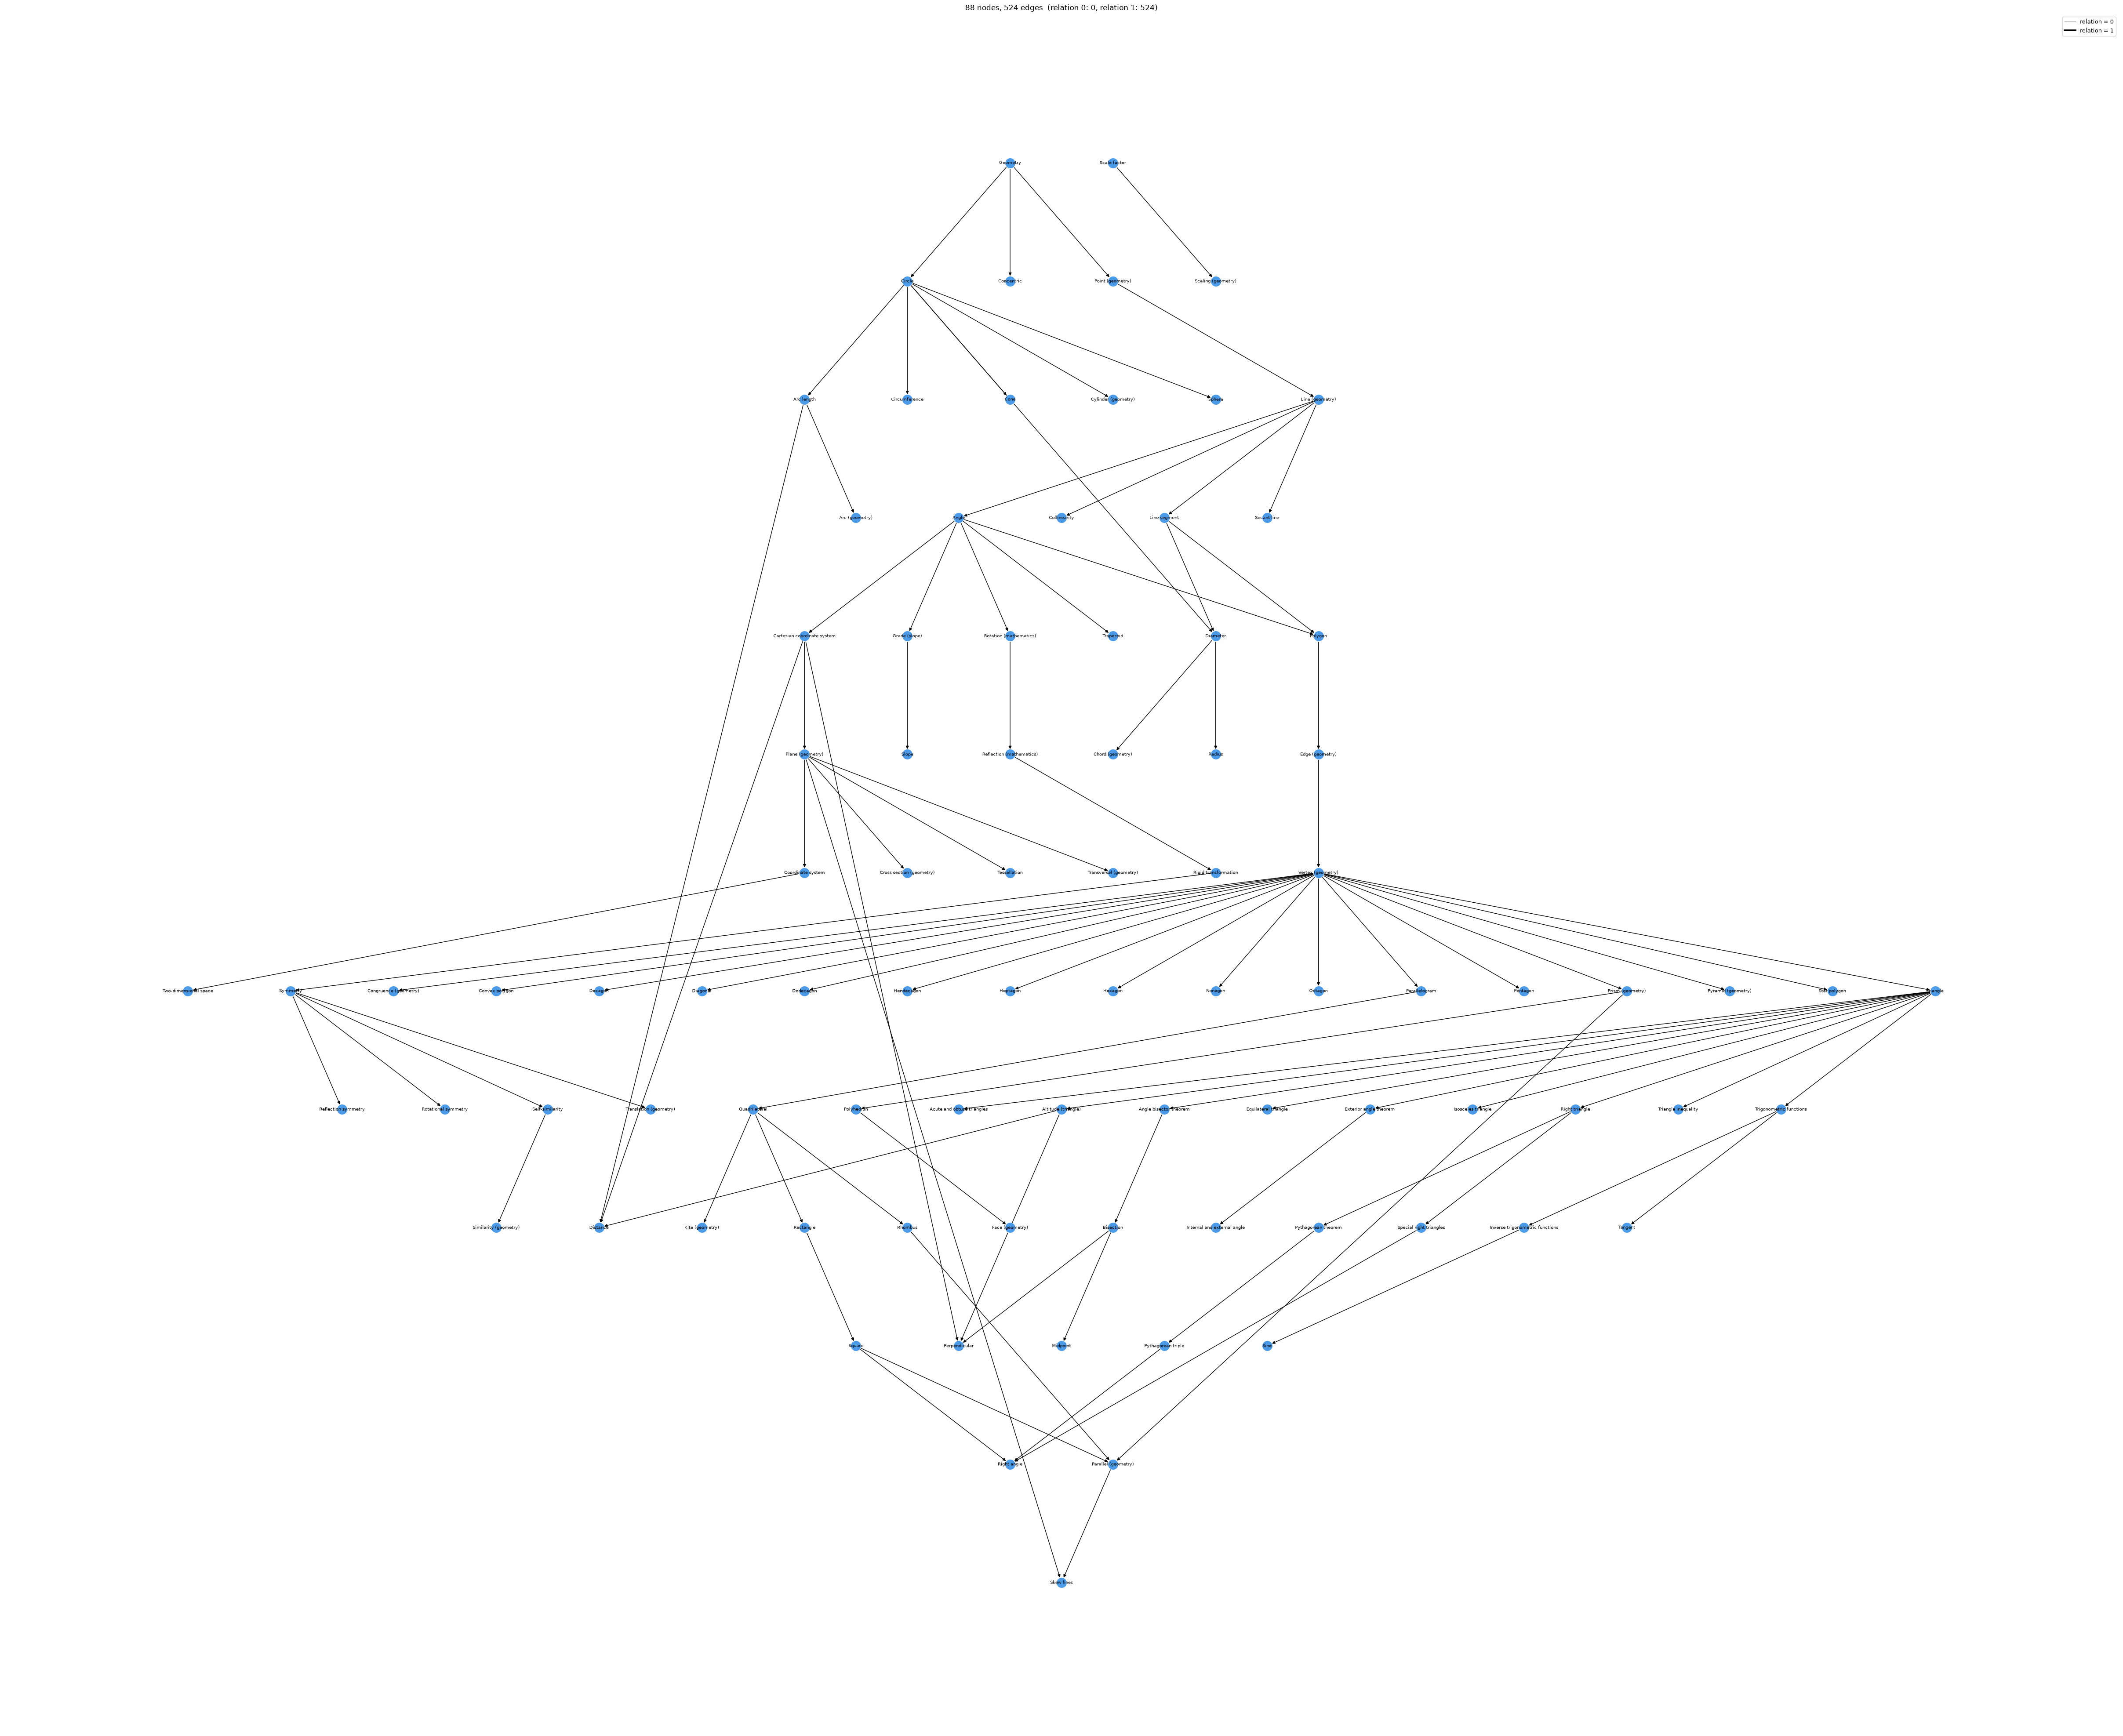

In [59]:
outfile = "../data/interim/PLD/Geometry/hierarchy.png"
level = {}
for v in nx.topological_sort(R):
    preds = list(R.predecessors(v))
    level[v] = 0 if not preds else max(level[p] + 1 for p in preds)

by_level = {}
for v, l in level.items():
    by_level.setdefault(l, []).append(v)

# order within each level by mean x-position of predecessors (top-down sweep)
for l in sorted(by_level):
    def key(v):
        preds = [p for p in R.predecessors(v) if p in by_level.get(level[p], [])]
        if not preds:
            return (0.0, v)
        xs = [by_level[level[p]].index(p) for p in preds]
        return (sum(xs) / len(xs), v)
    by_level[l].sort(key=key)

pos = {}
dx, dy = 1.8, 1.8
for l, nodes in by_level.items():
    for i, v in enumerate(nodes):
        x = (i - (len(nodes) - 1) / 2) * dx
        y = -l * dy
        pos[v] = (x, y)

labels = {node: node for node in G.nodes()}

fig, ax = plt.subplots(figsize=(max(11, n * 0.55), max(8, n * 0.45)))
nx.draw_networkx_edges(R, pos, ax=ax)

nx.draw_networkx_nodes(R, pos, ax=ax,
                        node_color="#4C9BE8", edgecolors="white",
                        linewidths=0.8)
nx.draw_networkx_labels(R, pos, labels=labels, ax=ax, font_size=7)
legend = [
    Line2D([0], [0], color="#999999", lw=0.9, label="relation = 0"),
    Line2D([0], [0], color="black", lw=2.8, label="relation = 1"),
]
ax.legend(handles=legend, loc="best", frameon=True, fontsize=9)
ax.set_title(
    f"{G.number_of_nodes()} nodes, {G.number_of_edges()} edges  "
    f"(relation 0: {len(edges_0)}, relation 1: {len(edges_1)})"
)
ax.axis("off")
fig.tight_layout()
fig.savefig(outfile, dpi=200, bbox_inches="tight")
print(f"Saved figure to {outfile}")
plt.show()